In [4]:
"""
Earth Engine extraction pipeline for Kharif 2026 (Chitradurga).
Extracts 12-day moving window S2 NDVI and S1 SAR features, masks non-vegetated
areas via Dynamic World 2026, and exports training CSV and inference rasters.
"""

from datetime import datetime, timedelta
import ee

ee.Initialize(project='shubhamk-463508')

# 1. Assets Definition(already uploaded as public asset to EE using GUI)
AOI = ee.FeatureCollection("projects/shubhamk-463508/assets/Chitradurga")
GT_POLYGONS = ee.FeatureCollection("projects/shubhamk-463508/assets/final_gt_polygons_chitradurga")
AOI_GEOM = AOI.geometry()

# 2. Dynamic World Kharif 2026 Active Vegetation Mask
# Avoids outdated landcover baselines by using the 2026 in-season active crop/vegetation probability
dw_col = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterBounds(AOI_GEOM)
    .filterDate("2026-06-01", "2026-10-30")
)

# Mean crop and vegetation probability during Kharif 2026
dw_crops = dw_col.select("crops").max()
# dw_grass = dw_col.select("grass").mean()
dw_active_veg = (
    dw_crops.gte(0.35).rename("active_veg_mask")
)  # Cropland & active vegetation threshold

# 3. Sentinel-2 L2A Cloud Masking via Cloud Score+
cs_plus = ee.ImageCollection(
    "GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED"
).filterBounds(AOI_GEOM).filterDate("2026-05-20", "2026-10-30")
s2_sr = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(AOI_GEOM).filterDate("2026-05-20", "2026-10-30")


def mask_s2_cs_plus(image):
    """Link Cloud Score+ Harmonized and mask pixels where cs < 0.60."""
    # Cloud Score+ matches Sentinel-2 granules by system:index
    cs_img = cs_plus.filter(
        ee.Filter.eq("system:index", image.get("system:index"))
    ).first()
    # cs band: 0 = high cloud/shadow, 1 = clear sky
    qa_mask = cs_img.select("cs").gte(0.60)

    # Compute NDVI only: (B8 - B4) / (B8 + B4)
    ndvi = image.updateMask(qa_mask).normalizedDifference(["B8", "B4"]).rename("NDVI")
    return ndvi.copyProperties(image, ["system:time_start"])


# 4. Sentinel-1 SAR Dual-Pol (VV, VH)
s1_col = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(AOI_GEOM)
    .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
    .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
    .filter(ee.Filter.eq("instrumentMode", "IW")).filterDate("2026-05-20", "2026-10-30")
)


def process_s1(img):
    vv = img.select("VV")
    vh = img.select("VH")
    vh_vv_ratio = (vh.subtract(vv)).rename("VH_VV_ratio")
    return img.select(["VV", "VH"]).addBands(vh_vv_ratio)


s1_processed = s1_col.map(process_s1)

# 5. 12-Day Moving Window Step Iteration (June 1 to November 30, 2026)
# Center date step = 12 days; Window = [center - 6 days, center + 6 days]
start_dt = datetime(2026, 6, 1)
end_dt = datetime(2026, 10, 30)
step_days = 12
window_half = 6

current_center = start_dt
composite_bands = []

print("[*] Generating 12-day composite windows...")
window_idx = 0
while current_center <= end_dt:
    w_start = (current_center - timedelta(days=window_half)).strftime(
        "%Y-%m-%d"
    )
    w_end = (current_center + timedelta(days=window_half)).strftime("%Y-%m-%d")
    tag = f"w{window_idx:02d}_{current_center.strftime('%m%d')}"

    # Optical: S2 NDVI median over 12-day window
    s2_win = (
        s2_sr.filterDate(w_start, w_end)
        .map(mask_s2_cs_plus)
        .median()
        .rename(f"NDVI_{tag}")
    )

    # SAR: S1 median over 12-day window
    s1_win = (
        s1_processed.filterDate(w_start, w_end)
        .median()
        .select(["VV", "VH", "VH_VV_ratio"])
    )
    s1_win = s1_win.regexpRename(".*", f"$0_{tag}")

    composite_bands.extend([s2_win, s1_win])

    current_center += timedelta(days=step_days)
    window_idx += 1

print(f"[✓] Created {window_idx} temporal intervals across the Kharif season.")

# 6. Assemble Stack and Apply Dynamic World Active Vegetation Mask
full_feature_stack = ee.Image.cat(composite_bands).clip(AOI_GEOM)
masked_feature_stack = full_feature_stack.updateMask(dw_active_veg)

# 7. Sample Ground Truth Polygons to Generate Training CSV
# Samples points inside GT polygons at 10m Sentinel resolution
training_samples = masked_feature_stack.unmask(-99).sampleRegions(
    collection=GT_POLYGONS,
    scale=10,
    geometries=True
)

# 8. Export Training Samples CSV to Google Drive
task_csv = ee.batch.Export.table.toDrive(
    collection=training_samples,
    description="chitradurga_gt_training_features_2026",
    folder="Chitradurga_Kharif_2026",
    fileFormat="CSV",
)
task_csv.start()
print(
    f"[*] Started Earth Engine Export Task: CSV Ground Truth Table -> Drive ID: {task_csv.id}"
)

# 9. Export District-Wide Multi-Band Raster for Inference
# Note: Uses crs 'EPSG:4326' or projected LCC to support local tile inference
task_raster = ee.batch.Export.image.toDrive(
    image=masked_feature_stack.toFloat(),
    description="chitradurga_kharif_2026_feature_stack",
    folder="Chitradurga_Kharif_2026",
    scale=10,  # 20m export scale provides balanced download size and field detail
    region=AOI_GEOM,
    maxPixels=1e13,
    fileFormat="GeoTIFF",
)
task_raster.start()
print(
    f"[*] Started Earth Engine Export Task: Inference Raster Stack -> Drive ID: {task_raster.id}"
)

[*] Generating 12-day composite windows...
[✓] Created 13 temporal intervals across the Kharif season.
[*] Started Earth Engine Export Task: CSV Ground Truth Table -> Drive ID: TUG5SPLVBJIWHIIAS3MGB7YA
[*] Started Earth Engine Export Task: Inference Raster Stack -> Drive ID: IPGIZU7NTA2IH2IRATVNABKV



--- GT Polygon Counts by Crop Class ---
raw_label
Maize          90
Ragi           72
Arecanut       50
Banana          8
Coconut         7
Cotton          6
Onion           5
Papaya          4
Chilli          2
Dragon          2
Basil           1
Marigold        1
Dragonfruit     1
Promogrante     1
Soybean         1
Name: id, dtype: int64

[✓] Classes retained independently (> 25 polygons): ['Maize', 'Ragi', 'Arecanut']

--- Final Aggregated Training Sample Distribution ---
model_class
Maize       2320
Ragi        2236
Arecanut    1709
Others       948
Name: count, dtype: int64

[*] Found 13 NDVI temporal steps and 39 SAR features.
[-] Removed 4328 samples with 100% missing optical sequences.

[*] Commencing 5-Fold Spatial Group Cross-Validation...

      LIGHTGBM SPATIAL GROUP CV METRICS (KHARIF 2026)
              precision    recall  f1-score   support

    Arecanut      0.767     0.818     0.792       581
       Maize      0.540     0.684     0.603       827
      Others      0.

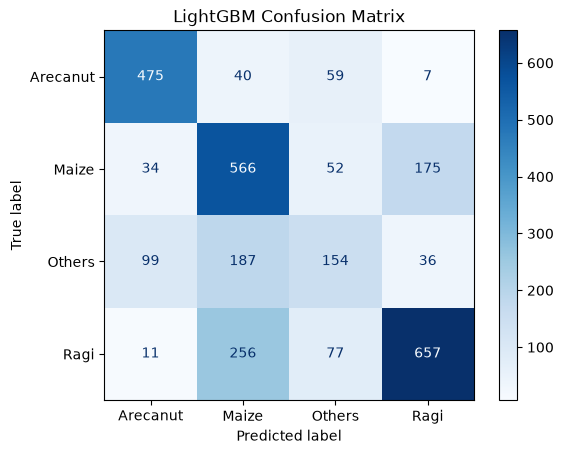


   RANDOM FOREST SPATIAL GROUP CV METRICS (KHARIF 2026)
              precision    recall  f1-score   support

    Arecanut      0.736     0.795     0.764       581
       Maize      0.524     0.693     0.597       827
      Others      0.456     0.269     0.338       476
        Ragi      0.727     0.641     0.682      1001

    accuracy                          0.626      2885
   macro avg      0.611     0.600     0.595      2885
weighted avg      0.626     0.626     0.617      2885

Cohen's Kappa (Random Forest): 0.484
Random Forest model feature importance:
                          feature  importance_mean
12                  NDVI_w12_1023         0.068293
11                  NDVI_w11_1011         0.021429
49           VV_w10_0929_w10_0929         0.019164
26           VH_w00_0601_w00_0601         0.012544
28           VH_w02_0625_w02_0625         0.009756
35           VH_w09_0917_w09_0917         0.009408
8                   NDVI_w08_0905         0.008188
18  VH_VV_ratio_w05_073

In [25]:
"""
Local preprocessing: Dynamic class grouping (polygons > 25), Savitzky-Golay
gap filling on 12-day NDVI curves, and Spatial Block CV model benchmark.
"""

import json
import re
import lightgbm as lgb
import numpy as np
import pandas as pd
from scipy.signal import savgol_filter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt



def prepare_gt_classes(
    df: pd.DataFrame,
    class_column_candidate: str = None,
    polygon_id_col: str = None,
    min_polygons: int = 25,
) -> pd.DataFrame:
    """Detects class labels and polygon identifiers, grouping classes with <= 25 polygons into 'Others'."""
    df = df.copy()

#     # Identify Class Column
#     if class_column_candidate is None:
#         for c in df.columns:
#             if any(k in c.lower() for k in ["crop", "class", "label", "target"]):
#                 class_column_candidate = c
#                 break
#     assert (
#         class_column_candidate in df.columns
#     ), "Target crop class column not found in dataset!"

#     # Identify Polygon/Field Identifier Column
#     if polygon_id_col is None:
#         for c in df.columns:
#             if any(k in c.lower() for k in ["poly", "field_id", "fid", "id"]):
#                 polygon_id_col = c
#                 break
#     if polygon_id_col is None:
#         print(
#             "[!] Warning: No explicit polygon ID column found. Using spatial clustering fallback."
#         )
#         # Spatial grouping proxy if single polygon ID not explicitly exported
#         df["polygon_id"] = (
#             (df[".geo"].astype(str).str.slice(0, 30))
#             if ".geo" in df.columns
#             else df.index
#         )
#         polygon_id_col = "polygon_id"

    # Normalize labels
    df["raw_label"] = (
        df[class_column_candidate]
        .astype(str)
        .str.strip()
        .str.title()
        .replace({"Nan": "Others", "": "Others"})
    )

    # Class distribution by distinct polygons
    poly_counts = (
        df.groupby("raw_label")[polygon_id_col]
        .nunique()
        .sort_values(ascending=False)
    )
    print("\n--- GT Polygon Counts by Crop Class ---")
    print(poly_counts)

    valid_classes = poly_counts[poly_counts > min_polygons].index.tolist()
    print(
        f"\n[✓] Classes retained independently (> {min_polygons} polygons): {valid_classes}"
    )

    # Recode remaining to 'Others'
    df["model_class"] = df["raw_label"].apply(
        lambda x: x if x in valid_classes else "Others"
    )

    print("\n--- Final Aggregated Training Sample Distribution ---")
    print(df["model_class"].value_counts())
    return df, polygon_id_col


def apply_savgol_to_ndvi_series(
    ndvi_matrix: np.ndarray, window_length: int = 5, polyorder: int = 2
):
    """Applies Savitzky-Golay filtering along the temporal axis.

    If an entire pixel sequence is NaN, it remains NaN (no hallucinated
    interpolation). Partial gaps are linearly interpolated before Savitzky-Golay
    smoothing.
    """
    n_samples, n_times = ndvi_matrix.shape
    filtered_matrix = np.full_like(ndvi_matrix, np.nan)

    for i in range(n_samples):
        series = ndvi_matrix[i, :].copy()

        # Check if all values in the time-series are masked
        valid_mask = ~np.isnan(series)
        valid_count = np.count_nonzero(valid_mask)

        if valid_count == 0:
            # Leave completely masked pixels as NaN
            continue

        if valid_count < (polyorder + 2):
            # Not enough points for polynomial fit; fill missing with mean of valid observations
            series[~valid_mask] = np.mean(series[valid_mask])
            filtered_matrix[i, :] = series
            continue

        # Linear interpolation for partial cloud gaps along the 12-day temporal axis
        if valid_count < n_times:
            x_indices = np.arange(n_times)
            series[~valid_mask] = np.interp(
                x_indices[~valid_mask],
                x_indices[valid_mask],
                series[valid_mask],
            )

        # Apply Savitzky-Golay filter
        # Ensure window length does not exceed sequence length and is odd
        actual_window = min(window_length, n_times)
        if actual_window % 2 == 0:
            actual_window -= 1

        smoothed = savgol_filter(
            series, window_length=actual_window, polyorder=polyorder
        )
        filtered_matrix[i, :] = np.clip(smoothed, -1.0, 1.0)

    return filtered_matrix


def run_pipeline(csv_path: str, class_col: str, poly_id_col: str):
    # 1. Load exported CSV
    df_raw = pd.read_csv(csv_path)
    df_raw.replace(-99, np.nan, inplace=True)

    # 2. Extract coordinates from .geo GeoJSON string if present
    if ".geo" in df_raw.columns and "longitude" not in df_raw.columns:
        coords = df_raw[".geo"].apply(
            lambda g: (
                json.loads(g)["coordinates"]
                if isinstance(g, str)
                else [np.nan, np.nan]
            )
        )
        df_raw["longitude"] = [c[0] for c in coords]
        df_raw["latitude"] = [c[1] for c in coords]

    # 3. Apply GT Class grouping
    df, poly_col = prepare_gt_classes(df_raw, class_col, poly_id_col, min_polygons=25)

    # 4. Extract 12-day NDVI features for Savitzky-Golay filtering
    ndvi_cols = sorted(
        [c for c in df.columns if c.startswith("NDVI_w")],
        key=lambda x: [
            int(s) if s.isdigit() else s for s in re.findall(r"\d+|\D+", x)
        ],
    )
    sar_cols = [
        c
        for c in df.columns
        if any(c.startswith(prefix) for prefix in ["VV_", "VH_", "VH_VV_ratio_"])
    ]

    print(
        f"\n[*] Found {len(ndvi_cols)} NDVI temporal steps and {len(sar_cols)} SAR features."
    )

    # 5. Apply Savitzky-Golay to the temporal NDVI stack
    raw_ndvi_matrix = df[ndvi_cols].values
    smoothed_ndvi_matrix = apply_savgol_to_ndvi_series(
        raw_ndvi_matrix, window_length=5, polyorder=2
    )

    # Overwrite NDVI columns with Savitzky-Golay smoothed data
    df_clean = df.copy()
    df_clean[ndvi_cols] = smoothed_ndvi_matrix

    # Remove rows where NDVI could not be recovered (all dates clouded/masked)
    valid_rows = ~np.isnan(df_clean[ndvi_cols].values).all(axis=1)
    df_clean = df_clean[valid_rows].reset_index(drop=True)
    print(
        f"[-] Removed {np.count_nonzero(~valid_rows)} samples with 100% missing optical sequences."
    )

    # 6. Fill minor SAR missing values (median fill)
    for c in sar_cols:
        df_clean[c] = df_clean[c].fillna(df_clean[c].median())

    # 7. Spatial Group Cross-Validation (5-Fold by Field / Polygon ID)
    # Using polygon groupings prevents data leakage between neighboring pixels of the same field
    feature_cols = ndvi_cols + sar_cols
    X = df_clean[feature_cols].values
    y = df_clean["model_class"].values
    groups = df_clean[poly_col].astype(str).values

    sgkf = StratifiedGroupKFold(n_splits=5)

    rf_model = RandomForestClassifier(
        n_estimators=300,
        max_depth=16,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1,
    )

    lgb_model = lgb.LGBMClassifier(
        n_estimators=250,
        learning_rate=0.05,
        num_leaves=31,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbose=-1,
    )

    rf_preds, lgb_preds, y_true = [], [], []

    print("\n[*] Commencing 5-Fold Spatial Group Cross-Validation...")
    for fold, (train_idx, val_idx) in enumerate(sgkf.split(X, y, groups=groups)):
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        rf_model.fit(X_train, y_train)
        rf_preds.extend(rf_model.predict(X_val))

        lgb_model.fit(X_train, y_train)
        lgb_preds.extend(lgb_model.predict(X_val))

        y_true.extend(y_val)

    # 8. Report Evaluation
    print("\n" + "=" * 65)
    print("      LIGHTGBM SPATIAL GROUP CV METRICS (KHARIF 2026)")
    print("=" * 65)
    print(classification_report(y_true, lgb_preds, digits=3))
    print(f"Cohen's Kappa (LightGBM): {cohen_kappa_score(y_true, lgb_preds):.3f}")
    print("LightGBM model feature importance:")
    print(pd.DataFrame({
        "feature": feature_cols,
        "importance_mean": permutation_importance(lgb_model, X_val, y_val, n_repeats=10, random_state=42).importances_mean
    }).sort_values("importance_mean", ascending=False).head(10))
    print("LGBM Confusion Matrix: ")
    cm = confusion_matrix(y_true, lgb_preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=lgb_model.classes_)
    disp.plot(cmap=plt.cm.Blues)
    plt.title("LightGBM Confusion Matrix")
    plt.show()
    
    
    print("\n" + "=" * 65)
    print("   RANDOM FOREST SPATIAL GROUP CV METRICS (KHARIF 2026)")
    print("=" * 65)
    print(classification_report(y_true, rf_preds, digits=3))
    print(
        f"Cohen's Kappa (Random Forest): {cohen_kappa_score(y_true, rf_preds):.3f}"
    )
    print("Random Forest model feature importance:")
    print(pd.DataFrame({
        "feature": feature_cols,
        "importance_mean": permutation_importance(rf_model, X_val, y_val, n_repeats=10, random_state=42).importances_mean
    }).sort_values("importance_mean", ascending=False).head(10))
    

    return lgb_model, feature_cols, list(np.unique(y))

feature_order=0
CSV_EXPORT_PATH = "chitradurga_gt_training_features_2026.csv"
model, features, classes = run_pipeline(CSV_EXPORT_PATH,'Crop','id')
feature_order=features

In [26]:
import joblib
import json
# Save model
joblib.dump(model, "lgb_model.pkl")


data_to_save = {
    "features": features,
    "classes": classes
}

with open('data', "w", encoding="utf-8") as f:
    json.dump(data_to_save, f)

print("Arrays successfully saved!")

Arrays successfully saved!


In [8]:
import joblib
import json
model = joblib.load("lgb_model.pkl")
# --- READ FROM FILE ---
with open('data', "r", encoding="utf-8") as f:
    loaded_data = json.load(f)

# Extract the individual arrays back
features = loaded_data["features"]
classes = loaded_data["classes"]

In [5]:
import glob
from osgeo import gdal


def create_vrt(input_dir: str, vrt_output_path: str):
    """Combines all GEE exported chunk GeoTIFFs into a single virtual raster without reading data into memory."""
    tif_files = sorted(glob.glob(f"{input_dir}/*.tif"))
    if not tif_files:
        raise FileNotFoundError(f"No GeoTIFFs found in {input_dir}")

    print(f"[*] Found {len(tif_files)} tiles. Building VRT...")

    # Build VRT
    vrt_options = gdal.BuildVRTOptions(resampleAlg="nearest")
    gdal.BuildVRT(vrt_output_path, tif_files, options=vrt_options)
    print(f"[✓] VRT successfully created at: {vrt_output_path}")


# Usage:
create_vrt(
    input_dir="chitradurga_raster/", vrt_output_path="district_stack.vrt"
)

[*] Found 11 tiles. Building VRT...


D:\Users\sunme\anaconda3\envs\geo\Lib\site-packages\osgeo\gdal.py:596: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


[✓] VRT successfully created at: district_stack.vrt


In [9]:
from datetime import datetime

# Get current date and time
now = datetime.now()

# Format and print only the time part (Hours:Minutes:Seconds)
current_time = now.strftime("%H:%M:%S")
print("Current Time:", current_time)

Current Time: 21:00:46
Current Time: 21:00:46
Current Time: 21:00:46


In [10]:
"""
Performs block-wise inference on the downloaded district GeoTIFF, applies
Savitzky-Golay filtering along temporal NDVI bands, and exports the crop
classification and Normalized Shannon Entropy rasters.
"""

import numpy as np
import pandas as pd
import rasterio
# from local_pipeline import apply_savgol_to_ndvi_series
import time

# Start the timer
start_time = time.perf_counter()

def process_district_raster(
    input_raster_path: str,
    output_crop_tif: str,
    output_entropy_tif: str,
    model,
    feature_names: list,
    class_labels: list,
):
    with rasterio.open(input_raster_path) as src:
        meta = src.meta.copy()
        band_names = list(src.descriptions)
        # Fallback if descriptions are blank: map feature names sequentially
        if not any(band_names):
            band_names = feature_names

        # Identify NDVI band indices in the raster
        ndvi_indices = [
            i for i, b in enumerate(band_names) if b.startswith("NDVI_w")
        ]
        feature_reorder_indices = [band_names.index(feat) for feat in feature_names]

        meta.update({"count": 1, "dtype": "uint8", "nodata": 0,'driver':'GTiff'})
        entropy_meta = meta.copy()
        entropy_meta.update({"dtype": "float32", "nodata": -9999.0})

        n_classes = len(class_labels)
        log_k = np.log(n_classes)

        with rasterio.open(
            output_crop_tif, "w", **meta
        ) as dst_crop, rasterio.open(
            output_entropy_tif, "w", **entropy_meta
        ) as dst_entropy:
            # Process block-by-block to control memory usage
            counter=0
            for ji, window in src.block_windows(1):
                block_start_time = time.perf_counter()
                block_data = src.read(window=window)  # shape: (bands, rows, cols)
                bands, rows, cols = block_data.shape
                
                

                # Flatten spatial dimensions
                flat_data = block_data.reshape(bands, -1).T  # (pixels, bands)

                # Mask invalid/no-data pixels (Dynamic World active veg mask)
                valid_mask = ~np.isnan(flat_data).all(axis=1)

                classified_block = np.zeros(rows * cols, dtype=np.uint8)
                entropy_block = np.full(
                    rows * cols, -9999.0, dtype=np.float32
                )

                if np.any(valid_mask):
                    valid_pixels = flat_data[valid_mask]

                    # 1. Apply local Savitzky-Golay to the 12-day NDVI slice
                    valid_pixels_ndvi = valid_pixels[:, ndvi_indices]
                    smoothed_ndvi = apply_savgol_to_ndvi_series(
                        valid_pixels_ndvi
                    )
                    valid_pixels[:, ndvi_indices] = smoothed_ndvi

                    # 2. Predict probabilities
                    probs = model.predict_proba(valid_pixels[:,feature_reorder_indices])
                    preds = (
                        np.argmax(probs, axis=1) + 1
                    )  # 1-indexed crop classes

                    # 3. Calculate Shannon Entropy: H = - sum(p * ln(p))
                    probs_clipped = np.clip(probs, 1e-7, 1.0)
                    entropy = -np.sum(
                        probs_clipped * np.log(probs_clipped), axis=1
                    )
                    norm_entropy = entropy / log_k

                    classified_block[valid_mask] = preds
                    entropy_block[valid_mask] = norm_entropy
                    

                # Write block
                dst_crop.write(
                    classified_block.reshape(rows, cols), 1, window=window
                )
                dst_entropy.write(
                    entropy_block.reshape(rows, cols), 1, window=window
                )
                
                block_end_time = time.perf_counter()
                block_execution_time = (block_end_time - block_start_time)/60
                counter=counter+1
                print(f"\rBlock: {counter}, Time: {block_execution_time}", end="", flush=True)

    print(f"[✓] Classification raster saved to: {output_crop_tif}")
    print(f"[✓] Normalized entropy raster saved to: {output_entropy_tif}")


def calculate_dynamic_area_table(
    classified_tif: str, class_labels: list, pixel_res_m: float = 20.0
) -> pd.DataFrame:
    """Calculates active agricultural mapped area by class."""
    with rasterio.open(classified_tif) as src:
        arr = src.read(1)

    pixel_ha = (pixel_res_m * pixel_res_m) / 10000.0
    total_valid_pixels = np.count_nonzero(arr > 0)
    total_mapped_ha = total_valid_pixels * pixel_ha

    records = []
    for idx, c_name in enumerate(class_labels, start=1):
        count = np.count_nonzero(arr == idx)
        ha = count * pixel_ha
        sqkm = ha / 100.0
        pct = (ha / total_mapped_ha) * 100 if total_mapped_ha > 0 else 0

        records.append(
            {
                "Class ID": idx,
                "Crop Class": c_name,
                "Pixel Count": count,
                "Area (Hectares)": round(ha, 2),
                "Area (Sq. Km)": round(sqkm, 2),
                "Share of Active Cropland (%)": round(pct, 2),
            }
        )

    return pd.DataFrame(records), total_mapped_ha

process_district_raster('district_stack.vrt','out.tif','out_prob.tif',model,feature_order,classes)
calculate_dynamic_area_table(classified_tif='out.tif', class_labels=classes, pixel_res_m=10.0)

end_time = time.perf_counter()
execution_time = (end_time - start_time)/60

print(f"Execution time: {execution_time} mins")

Block: 11049, Time: 0.19696010166662745-05[✓] Classification raster saved to: out.tif
[✓] Normalized entropy raster saved to: out_prob.tif
[✓] Classification raster saved to: out.tif
[✓] Normalized entropy raster saved to: out_prob.tif
[✓] Classification raster saved to: out.tif
[✓] Normalized entropy raster saved to: out_prob.tif
Execution time: 562.0979577133335 mins
Execution time: 562.0979577133335 mins
Execution time: 562.0979577133335 mins


In [15]:
"""
Clip final classified and probability raster since it has extra area after combining the exported
files downloaded from earth engine.
"""

import glob
from osgeo import gdal


def create_single_clipped_district_raster(shapefile_path: str):
    tif_files = ['out','out_prob']
    for file in tif_files:
        warp_options = gdal.WarpOptions(
            format="GTiff",
            cutlineDSName=shapefile_path,  # Automatically detects LCC from .prj and reprojects
            cropToCutline=True,  # Crops output extent to shapefile boundary
            dstNodata=-9999.0,  # Sets pixels outside Chitradurga to NoData
            creationOptions=[
                "COMPRESS=LZW",  # Keeps file size small
                "TILED=YES",
                "BIGTIFF=YES",  # Prevents 4GB GeoTIFF file size limit crashes
            ],
            multithread=True,  # Uses all CPU cores
        )

        gdal.Warp(file+'_clip.tif', file+'.tif', options=warp_options)

    # Clean up temporary VRT file
    print(
        f"[✓] Successfully created clipped output GeoTIFF"
    )


create_single_clipped_district_raster(shapefile_path="Chitradurga_District/Chitradurga.shp")

D:\Users\sunme\anaconda3\envs\geo\Lib\site-packages\osgeo\gdal.py:596: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(
D:\Users\sunme\anaconda3\envs\geo\Lib\site-packages\osgeo\gdal.py:596: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(
D:\Users\sunme\anaconda3\envs\geo\Lib\site-packages\osgeo\gdal.py:596: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


[✓] Successfully created clipped output GeoTIFF
[✓] Successfully created clipped output GeoTIFF
[✓] Successfully created clipped output GeoTIFF


In [16]:
records,total_area=calculate_dynamic_area_table(classified_tif='out_clip.tif', class_labels=classes, pixel_res_m=10.0)
records.to_csv('area_stats.csv')

In [20]:
"""
Generates an interactive, standalone HTML map for Chitradurga Kharif 2026 using
Folium. Dynamically converts GeoTIFF rasters into georeferenced RGBA PNG
overlays (4 classes: Arecanut, Maize, Ragi, Others) and renders area metrics
from 'area_stats.csv'.
"""

import os
import branca
import folium
import matplotlib
import numpy as np
import pandas as pd
from PIL import Image
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import transform_bounds


# -----------------------------------------------------------------------------
# 1. COLOR DEFINITIONS FOR THE 4 CLASSES
# -----------------------------------------------------------------------------
# Class 1: Arecanut | Class 2: Maize | Class 3: Ragi | Class 4: Others
CLASS_CONFIG = {
    1: {"name": "Arecanut", "color_hex": "#1B5E20", "rgba": (27, 94, 32, 230)},
    2: {"name": "Maize", "color_hex": "#FFB300", "rgba": (255, 179, 0, 230)},
    3: {"name": "Ragi", "color_hex": "#8D6E63", "rgba": (141, 110, 99, 230)},
    4: {"name": "Others", "color_hex": "#78909C", "rgba": (120, 144, 156, 220)},
}


# -----------------------------------------------------------------------------
# 2. RASTER TO PNG CONVERSION UTILITIES
# -----------------------------------------------------------------------------
def get_wgs84_bounds(src) -> list:
    """Returns [[min_lat, min_lon], [max_lat, max_lon]] in EPSG:4326 for Folium."""
    left, bottom, right, top = src.bounds
    if src.crs and src.crs.to_string() != "EPSG:4326":
        left, bottom, right, top = transform_bounds(
            src.crs, "EPSG:4326", left, bottom, right, top
        )
    return [[bottom, left], [top, right]]


def export_classification_to_rgba_png(
    input_tif: str, output_png: str, max_dimension: int = 3000
) -> list:
    """Converts discrete 4-class classification GeoTIFF to an RGBA transparent PNG."""
    with rasterio.open(input_tif) as src:
        bounds = get_wgs84_bounds(src)

        # Scale down if needed to prevent browser memory exhaustion
        scale = min(1.0, max_dimension / max(src.width, src.height))
        out_shape = (int(src.height * scale), int(src.width * scale))

        arr = src.read(
            1,
            out_shape=out_shape,
            resampling=Resampling.nearest,  # Preserve categorical class IDs
        )

        h, w = arr.shape
        rgba = np.zeros((h, w, 4), dtype=np.uint8)

        # Map each class to RGBA
        for class_id, cfg in CLASS_CONFIG.items():
            mask = arr == class_id
            rgba[mask] = cfg["rgba"]

        # Pixel value 0 (NoData / Masked non-cropland) remains alpha = 0 (100% transparent)
        img = Image.fromarray(rgba, "RGBA")
        img.save(output_png, "PNG", optimize=True)
        print(f"[✓] Converted classification raster -> {output_png}")
        return bounds


def export_uncertainty_to_rgba_png(
    input_tif: str, output_png: str, max_dimension: int = 3000
) -> list:
    """Converts Normalized Shannon Entropy / Probability GeoTIFF to a colored heatmap PNG."""
    with rasterio.open(input_tif) as src:
        bounds = get_wgs84_bounds(src)

        scale = min(1.0, max_dimension / max(src.width, src.height))
        out_shape = (int(src.height * scale), int(src.width * scale))

        arr = src.read(1, out_shape=out_shape, resampling=Resampling.bilinear)

        # Valid entropy is [0.0, 1.0]; NoData is typically -9999.0 or NaN
        nodata_val = src.nodata if src.nodata is not None else -9999.0
        valid_mask = (arr != nodata_val) & ~np.isnan(arr) & (arr >= 0.0)

        # Normalize valid values between 0.0 (Certain - Green) to 1.0 (Ambiguous - Red)
        norm_arr = np.clip(arr, 0.0, 1.0)

        colormap = matplotlib.colormaps["RdYlGn_r"]  # Red = high uncertainty, Green = low
        rgba_float = colormap(norm_arr)  # Shape (H, W, 4) in range [0, 1]
        rgba = (rgba_float * 255).astype(np.uint8)

        # Apply transparency: 0.65 opacity for valid pixels, 0 for NoData
        rgba[valid_mask, 3] = 165
        rgba[~valid_mask, :] = [0, 0, 0, 0]

        img = Image.fromarray(rgba, "RGBA")
        img.save(output_png, "PNG", optimize=True)
        print(f"[✓] Converted uncertainty raster -> {output_png}")
        return bounds


# -----------------------------------------------------------------------------
# 3. CSV STATISTICS INGESTION
# -----------------------------------------------------------------------------
def load_and_render_stats_html(csv_path: str) -> str:
    """Reads 'area_stats.csv' dynamically and builds a formatted HTML snippet."""
    if not os.path.exists(csv_path):
        return "<p style='color:red;'>⚠️ 'area_stats.csv' not found.</p>"

    df = pd.read_csv(csv_path)

    # Format numeric columns cleanly if present
    for col in df.columns:
        if "ha" in col.lower() or "hectare" in col.lower():
            df[col] = df[col].apply(
                lambda x: f"{x:,.1f}" if isinstance(x, (int, float)) else str(x)
            )
        elif "sq" in col.lower() or "km" in col.lower():
            df[col] = df[col].apply(
                lambda x: f"{x:,.2f}" if isinstance(x, (int, float)) else str(x)
            )
        elif (
            "%" in col
            or "share" in col.lower()
            or "percentage" in col.lower()
        ):
            df[col] = df[col].apply(
                lambda x: f"{x:.2f}%" if isinstance(x, (int, float)) else str(x)
            )

    table_html = df.to_html(
        classes="stats-table",
        index=False,
        border=0,
        justify="left",
    )
    return table_html


# -----------------------------------------------------------------------------
# 4. MAIN FOLIUM MAP GENERATOR
# -----------------------------------------------------------------------------
def build_interactive_folium_map(
    crop_tif: str = "chitradurga_crop_classification_2026.tif",
    uncertainty_tif: str = "chitradurga_uncertainty_2026.tif",
    stats_csv: str = "area_stats.csv",
    output_html: str = "chitradurga_crop_map_2026.html",
):
    print("[*] Generating PNG overlays from GeoTIFF rasters...")
    crop_png = "overlay_crop_classified.png"
    unc_png = "overlay_uncertainty.png"

    crop_bounds = export_classification_to_rgba_png(crop_tif, crop_png)
    unc_bounds = export_uncertainty_to_rgba_png(uncertainty_tif, unc_png)

    # Center map around Chitradurga coordinates
    center_lat = (crop_bounds[0][0] + crop_bounds[1][0]) / 2.0
    center_lon = (crop_bounds[0][1] + crop_bounds[1][1]) / 2.0

    print(
        f"[*] Initializing Folium map centered at [{center_lat:.4f}, {center_lon:.4f}]..."
    )
    m = folium.Map(
        location=[center_lat, center_lon],
        zoom_start=10,
        tiles=None,
        control_scale=True,
    )
    m.fit_bounds(crop_bounds)

    # Add Basemaps
    
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
        attr="Esri Street Maps",
        name="Street Maps (Esri)",
        overlay=False,
        control=True,
        show=True
    ).add_to(m)
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
        attr="Esri World Imagery",
        name="Satellite Basemap (Esri)",
        overlay=False,
        control=True,
        show=False
    ).add_to(m)

    # Add Prediction Raster Overlays
    folium.raster_layers.ImageOverlay(
        image=crop_png,
        bounds=crop_bounds,
        name="Kharif 2026 Crops (Arecanut, Maize, Ragi, Others)",
        opacity=0.9,
        interactive=True,
        show=True,
    ).add_to(m)

    folium.raster_layers.ImageOverlay(
        image=unc_png,
        bounds=unc_bounds,
        name="Shannon Entropy (Uncertainty Heatmap)",
        opacity=0.75,
        interactive=True,
        show=False,  # Unchecked by default
    ).add_to(m)

    # Layer Switcher
    folium.LayerControl(position="topright", collapsed=False).add_to(m)

    # Ingest dynamic area statistics HTML from area_stats.csv
    stats_table_html = load_and_render_stats_html(stats_csv)

    # Floating UI Panel (Legend + Ingested CSV Table)
    floating_panel_html = f"""
    <div id="info-panel" class="leaflet-control">
        <div class="panel-header">
            <h4>Chitradurga Kharif 2026</h4>
            <span class="sub-title">Crop Classification & Area Accounting</span>
        </div>
        
        <div class="section-title">Mapped Classes</div>
        <div class="legend-grid">
            <div><span class="swatch" style="background:{CLASS_CONFIG[1]['color_hex']};"></span> Arecanut</div>
            <div><span class="swatch" style="background:{CLASS_CONFIG[2]['color_hex']};"></span> Maize</div>
            <div><span class="swatch" style="background:{CLASS_CONFIG[3]['color_hex']};"></span> Ragi</div>
            <div><span class="swatch" style="background:{CLASS_CONFIG[4]['color_hex']};"></span> Others</div>
        </div>

        <div class="section-title">Uncertainty Scale (Entropy)</div>
        <div class="entropy-bar-container">
            <div class="entropy-bar"></div>
            <div class="entropy-labels">
                <span>0.0 (Certain)</span>
                <span>0.5</span>
                <span>1.0 (Ambiguous)</span>
            </div>
        </div>

        <div class="section-title">District Statistics (Source: area_stats.csv)</div>
        <div class="table-container">
            {stats_table_html}
        </div>
        <div class="footer-note">*Masked by Dynamic World 2026 active vegetation.</div>
    </div>

    <style>
        #info-panel {{
            position: fixed;
            bottom: 25px;
            left: 25px;
            width: 380px;
            max-height: 85vh;
            background: rgba(255, 255, 255, 0.96);
            padding: 16px 20px;
            border-radius: 10px;
            box-shadow: 0 4px 18px rgba(0,0,0,0.25);
            font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Arial, sans-serif;
            color: #212121;
            z-index: 1000;
            overflow-y: auto;
        }}
        .panel-header h4 {{
            margin: 0;
            font-size: 17px;
            font-weight: 700;
            color: #1b5e20;
        }}
        .sub-title {{
            font-size: 12px;
            color: #616161;
            margin-bottom: 10px;
            display: inline-block;
        }}
        .section-title {{
            font-size: 13px;
            font-weight: 600;
            margin: 12px 0 6px 0;
            border-bottom: 1px solid #e0e0e0;
            padding-bottom: 3px;
            color: #37474f;
        }}
        .legend-grid {{
            display: grid;
            grid-template-columns: 1fr 1fr;
            gap: 6px;
            font-size: 12px;
            font-weight: 500;
        }}
        .swatch {{
            display: inline-block;
            width: 14px;
            height: 14px;
            vertical-align: middle;
            margin-right: 6px;
            border-radius: 3px;
            border: 1px solid rgba(0,0,0,0.15);
        }}
        .entropy-bar-container {{
            margin-top: 4px;
        }}
        .entropy-bar {{
            height: 10px;
            border-radius: 4px;
            background: linear-gradient(to right, #2ecc71, #f1c40f, #e74c3c);
        }}
        .entropy-labels {{
            display: flex;
            justify-content: space-between;
            font-size: 10px;
            color: #757575;
            margin-top: 2px;
        }}
        .table-container {{
            margin-top: 6px;
            max-height: 220px;
            overflow-y: auto;
        }}
        .stats-table {{
            width: 100%;
            border-collapse: collapse;
            font-size: 11px;
            text-align: left;
        }}
        .stats-table th {{
            background-color: #eceff1;
            padding: 6px 8px;
            font-weight: 600;
            color: #37474f;
            position: sticky;
            top: 0;
        }}
        .stats-table td {{
            padding: 5px 8px;
            border-bottom: 1px solid #f0f0f0;
        }}
        .stats-table tr:hover {{
            background-color: #f5f5f5;
        }}
        .footer-note {{
            font-size: 10px;
            color: #9e9e9e;
            margin-top: 8px;
            font-style: italic;
        }}
    </style>
    """

    m.get_root().html.add_child(folium.Element(floating_panel_html))

    # Save standalone map
    m.save(output_html)
    print(f"\n[✓] Standalone interactive HTML map successfully exported to: {output_html}")


build_interactive_folium_map(
        crop_tif="out_clip.tif",
        uncertainty_tif="out_prob_clip.tif",
        stats_csv="area_stats.csv",
        output_html="chitradurga_crop_map_2026.html",
    )

[*] Generating PNG overlays from GeoTIFF rasters...
[*] Generating PNG overlays from GeoTIFF rasters...
[*] Generating PNG overlays from GeoTIFF rasters...
[✓] Converted classification raster -> overlay_crop_classified.png
[✓] Converted classification raster -> overlay_crop_classified.png
[✓] Converted classification raster -> overlay_crop_classified.png
[✓] Converted uncertainty raster -> overlay_uncertainty.png
[*] Initializing Folium map centered at [14.3060, 76.5244]...
[✓] Converted uncertainty raster -> overlay_uncertainty.png
[*] Initializing Folium map centered at [14.3060, 76.5244]...
[✓] Converted uncertainty raster -> overlay_uncertainty.png
[*] Initializing Folium map centered at [14.3060, 76.5244]...

[✓] Standalone interactive HTML map successfully exported to: chitradurga_crop_map_2026.html

[✓] Standalone interactive HTML map successfully exported to: chitradurga_crop_map_2026.html

[✓] Standalone interactive HTML map successfully exported to: chitradurga_crop_map_2026.